In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

In [2]:
DATA_RAW = Path.cwd().parent
df = pd.read_csv(DATA_RAW/"data"/"raw"/"dataset.csv",encoding="utf-8")

In [3]:
df_clean = (
    df.fillna(df['CREDIT_LIMIT'].median())
    .drop_duplicates()
    .copy()
)

df_clean.to_csv(
    "df_clean.csv",
    index=False
)

In [4]:
df_prepare_clustering = df_clean.copy()
df_prepare_clustering = df_prepare_clustering.drop('CUST_ID', axis=1)

In [5]:
numeric_columns = df_prepare_clustering.select_dtypes(include=[np.number]).columns.tolist()
# df_prepare_clustering[numeric_columns] = np.log1p(
#     df_prepare_clustering[numeric_columns]
# )

compare the deferent before implenting logarithmic transformation skew

In [6]:
df[numeric_columns].skew() - df_prepare_clustering[numeric_columns].skew()

BALANCE                   0.000000
PURCHASES                 0.000000
ONEOFF_PURCHASES          0.000000
INSTALLMENTS_PURCHASES    0.000000
CASH_ADVANCE              0.000000
CREDIT_LIMIT             -0.000172
PAYMENTS                  0.000000
dtype: float64

RAW DATA
   │
   ▼
Select clustering features
   │
   ▼
Handle missing values
   │
   ▼
Analyze distributions and outliers
   │
   ▼
log1p (selected skewed columns only)
   │
   ▼
StandardScaler
   │
   ▼
PCA (all available components)
   │
   ▼
Calculate explained variance
   │
   ▼
Calculate cumulative variance
   │
   ▼
Select minimum components exceeding 80%
   │
   ▼
Final PCA transformation
   │
   ▼
X_pca

In [7]:
%pip install scikit-learn

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [8]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA

preprocessor = ColumnTransformer(
    transformers=[
        (
            "log",
            FunctionTransformer(np.log1p),
            numeric_columns
        ),
    ],
    remainder="drop"
)

In [9]:
pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("scaler", StandardScaler()),
        ("pca", PCA(n_components=0.80, svd_solver="full", whiten=False,))
    ]
)
X_pca_all = pipeline.fit_transform(df_prepare_clustering)

Maintenant que nous avons `X_pca`, qui contient les composantes principales sélectionnées (en l'occurrence, celles qui expliquent au moins 80% de la variance), vous pouvez l'utiliser comme entrée pour votre algorithme de clustering (par exemple, K-Means, DBSCAN, etc.). Ces données réduites en dimensionnalité sont prêtes pour l'étape de clustering.

In [10]:
pca = pipeline.named_steps["pca"]
print("Selected components:", pca.n_components_)
print("Retained variance:", pca.explained_variance_ratio_.sum())

Selected components: 4
Retained variance: 0.8602631837242027


RuntimeError: `robust=True` requires statsmodels, an optional dependency, to be installed.

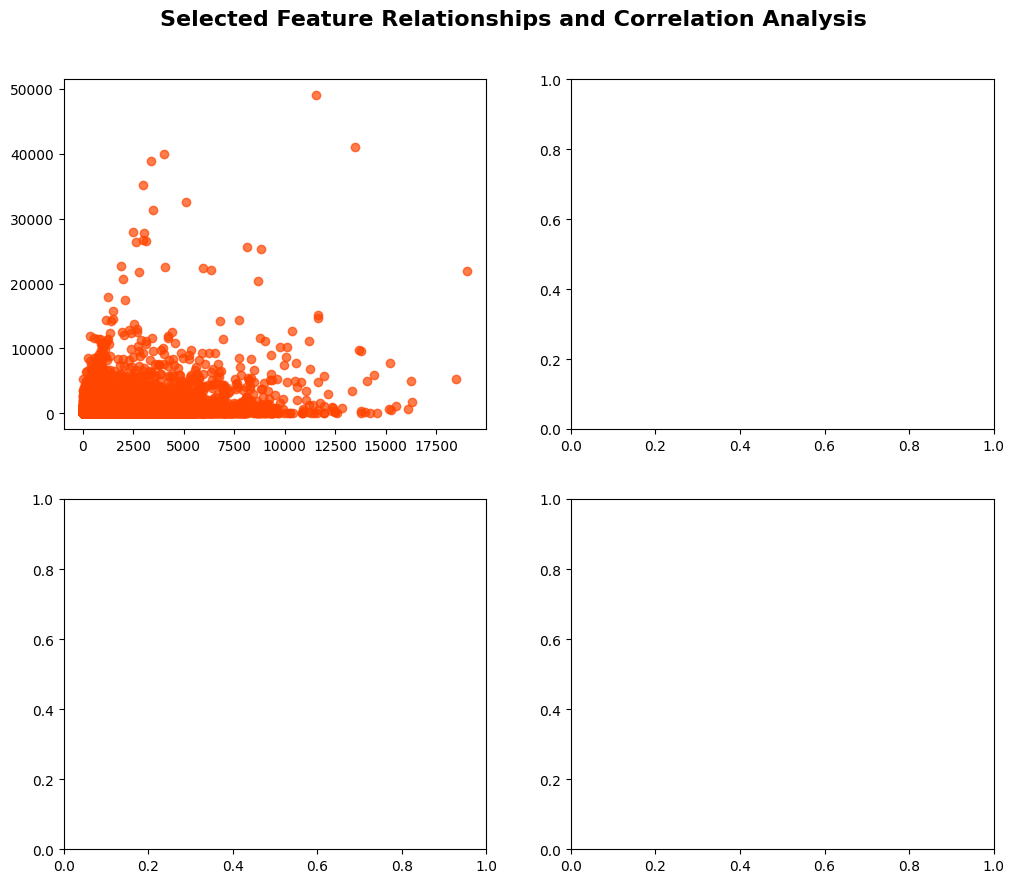

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
fig.suptitle('Selected Feature Relationships and Correlation Analysis',fontsize=16,weight='bold',y=0.95)

axes = axes.flatten()

regplot_settings = [
    ('BALANCE', 'PURCHASES', 'orangered', 'Account Balance', 'Total Purchases'),
    ('BALANCE', 'PAYMENTS', 'steelblue', 'Account Balance', 'Total Payments'),
    ('PURCHASES', 'PAYMENTS', 'darkorange', 'Total Purchases', 'Total Payments')
]
for i, (x, y, color, xlabel, ylabel) in enumerate(regplot_settings):
    sns.regplot(data=df_prepare_clustering, x=x,y=y,color=color, ax=axes[i],scatter_kws={'alpha': 0.7},line_kws={'linewidth': 2},robust=True)
    axes[i].set(title=f'{x} vs {y}',xlabel=xlabel,ylabel=ylabel)
    axes[i].grid(True, linestyle='--', alpha=0.5)

# Hide any unused subplots
for i in range(len(regplot_settings), len(axes)):
    fig.delaxes(axes[i])

plt.tight_layout(rect=[0, 0.03, 1, 0.92])
plt.show()

In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, calinski_harabasz_score

K = range(2,10)

inertia = []
silhouette = []
calinski = []

for k in K:
    km = KMeans(n_clusters=k, init='k-means++', n_init=1000, random_state=42)
    labels = km.fit_predict(X_pca_all)

    # Elbow (WCSS)
    inertia.append(km.inertia_)

    # Silhouette Score
    silhouette.append(silhouette_score(X_pca_all, labels))

    # Calinski-Harabasz Index
    calinski.append(calinski_harabasz_score(X_pca_all, labels))

In [ ]:
for k, i, s, c in zip(K, inertia, silhouette, calinski):
    print(f"K={k:<2} | WCSS={i:.2f} | Silhouette={s:.4f} | CH={c:.2f}")

In [ ]:
from kneed import KneeLocator
kneedle = KneeLocator(K, inertia, curve='convex', direction='decreasing')
optimal_k = kneedle.elbow
print(f"Optimal K (Elbow): {optimal_k}")

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))


axes[0].plot(K, inertia, marker="o")
axes[0].set_title("Elbow Method (WCSS)")
axes[0].set_xlabel("Number of Clusters (K)")
axes[0].set_ylabel("WCSS (Inertia)")

if optimal_k is not None:
     axes[0].axvline(optimal_k, linestyle="--", color="green")

axes[1].plot(K, silhouette, marker="o")
axes[1].set_title("Silhouette Score")
axes[1].set_xlabel("Number of Clusters (K)")
axes[1].set_ylabel("Score")


axes[2].plot(K, calinski, marker="o")
axes[2].set_title("Calinski-Harabasz Score")
axes[2].set_xlabel("Number of Clusters (K)")
axes[2].set_ylabel("Score")


plt.tight_layout()
plt.show()

In [ ]:
kmeans3 = KMeans(n_clusters=3,init='k-means++',n_init=1000,random_state=42)
kmeans3.fit(X_pca_all)

In [ ]:
kmeans4 = KMeans(n_clusters=4,init='k-means++',n_init=1000,random_state=42)
kmeans4.fit(X_pca_all)

In [ ]:
df_clean["cluster"] = kmeans3.labels_

In [ ]:
df_clean.head(10)

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Create a visualization DataFrame
pca_df = pd.DataFrame(
    X_pca_all[:, :2],
    columns=["PC1", "PC2"]
)

pca_df["K3"] = kmeans3.labels_
pca_df["K4"] = kmeans4.labels_

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# K = 3
sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="K3",
    palette="tab10",
    s=15,
    alpha=0.6,
    ax=axes[0]
)

# Plot K=3 cluster centers
axes[0].scatter(
    kmeans3.cluster_centers_[:, 0],
    kmeans3.cluster_centers_[:, 1],
    marker='X',
    s=200,
    color='black',
    label='Cluster Centers'
)
axes[0].set_title("KMeans - K=3")

# K = 4
sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="K4",
    palette="tab10",
    s=15,
    alpha=0.6,
    ax=axes[1]
)

# Plot K=4 cluster centers
axes[1].scatter(
    kmeans4.cluster_centers_[:, 0],
    kmeans4.cluster_centers_[:, 1],
    marker='X',
    s=200,
    color='black',
    label='Cluster Centers'
)
axes[1].set_title("KMeans - K=4")

plt.tight_layout()
plt.show()

Implementation of DBSCAN algo

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.neighbors import NearestNeighbors

min_samples = 5

neighbors = NearestNeighbors(
    n_neighbors=min_samples
)

neighbors.fit(X_pca_all)

distances, indices = neighbors.kneighbors(X_pca_all)
k_distances = np.sort(distances[:, -1])

plt.figure(figsize=(10, 5))

plt.plot(k_distances)

plt.xlabel("Observations (sorted)")
plt.ylabel("5th Nearest Neighbor Distance")
plt.title("K-Distance Plot for DBSCAN")

plt.grid(True)

plt.show()

In [ ]:
eps_values = [0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
min_samples_values = range(3,11)

In [ ]:
x_values = range(len(k_distances))

# Find the elbow/knee point on the k-distance plot
kneedle = KneeLocator(x_values, k_distances, curve='convex', direction='increasing')
optimal_idx = kneedle.elbow
optimal_eps = k_distances[optimal_idx] if optimal_idx is not None else None

print(f"Optimal index: {optimal_idx}")
print(f"Optimal eps (Elbow): {optimal_eps:.4f}")

In [ ]:
knee_results = []

for min_samples in min_samples_values:

    # Calculate distances
    neighbors = NearestNeighbors(
        n_neighbors=min_samples
    )

    neighbors.fit(X_pca_all)

    distances, _ = neighbors.kneighbors(X_pca_all)
    # Sort distances
    k_distances = np.sort(distances[:, -1])

    # Find elbow
    x_values = np.arange(len(k_distances))

    kneedle = KneeLocator(
        x_values,
        k_distances,
        curve="convex",
        direction="increasing"
    )

    optimal_idx = kneedle.elbow

    optimal_eps = (
        float(k_distances[optimal_idx])
        if optimal_idx is not None
        else np.nan
    )

    knee_results.append({
        "min_samples": min_samples,
        "optimal_eps": optimal_eps
    })

df_knee = pd.DataFrame(knee_results)

display(df_knee)

In [ ]:
from sklearn.cluster import DBSCAN
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

final_dbscan = DBSCAN(eps=0.6, min_samples=9)
df_clean["dbscan_cluster"] = final_dbscan.fit_predict(X_pca_all)

final_summary = df_clean.groupby("dbscan_cluster").agg(
    Customers=("dbscan_cluster", "size"),
    Avg_Balance=("BALANCE", "mean"),
    Avg_Purchases=("PURCHASES", "mean"),
    Avg_Credit_Limit=("CREDIT_LIMIT", "mean"),
    Avg_Payments=("PAYMENTS", "mean")
).round(2)

In [ ]:
import numpy as np
import pandas as pd

from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

def validate_clustering_input(X, labels):

    X = np.asarray(X, dtype=float)
    labels = np.asarray(labels)

    if X.ndim != 2:
        raise ValueError("X must be a 2D array.")

    if labels.ndim != 1:
        raise ValueError("Labels must be a 1D array.")

    if len(X) != len(labels):
        raise ValueError(
            "X and labels must have the same number of observations."
        )

    if len(X) == 0:
        raise ValueError("The dataset cannot be empty.")

    if not np.isfinite(X).all():
        raise ValueError("X contains NaN or infinite values.")

    if pd.isna(labels).any():
        raise ValueError("Labels contain missing values.")

    return X, labels


def is_valid_clustering(labels):

    n_samples = len(labels)
    n_clusters = len(np.unique(labels))

    return 2 <= n_clusters < n_samples

def calculate_silhouette(X, labels):

    if not is_valid_clustering(labels):
        return np.nan

    return silhouette_score(X, labels)


def calculate_davies_bouldin(X, labels):

    if not is_valid_clustering(labels):
        return np.nan

    return davies_bouldin_score(X, labels)


def calculate_calinski_harabasz(X, labels):

    if not is_valid_clustering(labels):
        return np.nan

    return calinski_harabasz_score(X, labels)

def calculate_cluster_counts(labels):

    return (
        pd.Series(labels)
        .value_counts()
        .sort_index()
    )


def calculate_cluster_proportions(labels):

    return (
        pd.Series(labels)
        .value_counts(normalize=True)
        .sort_index()
    )

def calculate_noise_rate(labels):

    labels = np.asarray(labels)

    if len(labels) == 0:
        return np.nan

    return np.mean(labels == -1)

def evaluate_clustering(X, labels, exclude_noise=False):

    # Validate input
    X, labels = validate_clustering_input(X, labels)

    # Calculate full distribution
    counts = calculate_cluster_counts(labels)

    proportions = calculate_cluster_proportions(labels)

    # DBSCAN-specific preprocessing
    if exclude_noise:

        noise_rate = calculate_noise_rate(labels)

        mask = labels != -1

        X_eval = X[mask]
        labels_eval = labels[mask]

    else:

        noise_rate = np.nan

        X_eval = X
        labels_eval = labels

    # Calculate metrics
    return {
        "n_clusters": len(np.unique(labels_eval)),

        "n_evaluated": len(labels_eval),

        "silhouette": calculate_silhouette(
            X_eval, labels_eval
        ),

        "davies_bouldin": calculate_davies_bouldin(
            X_eval, labels_eval
        ),

        "calinski_harabasz": calculate_calinski_harabasz(
            X_eval, labels_eval
        ),

        "noise_rate": noise_rate,

        "cluster_counts": counts,

        "cluster_proportions": proportions
    }

In [ ]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    x=X_pca_all[:, 0],
    y=X_pca_all[:, 1],
    hue=df_clean["dbscan_cluster"],
    palette="bright",
    alpha=0.7,
    s=25
)

plt.title("Visualisation des Clusters DBSCAN (eps=0.6, min_samples=9)", fontsize=14, fontweight='bold')
plt.xlabel("Première Composante Principale (PC1)")
plt.ylabel("Deuxième Composante Principale (PC2)")
plt.legend(title="Cluster (Note: -1 = Bruit)", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

In [ ]:
results_k3 = evaluate_clustering(
    X_pca_all,
    kmeans3.labels_
)
results_dbscan = evaluate_clustering(
    X_pca_all,
    final_dbscan.labels_,
    exclude_noise=True
)